## <img style="float: left; padding-right: 10px; width: 100px" src="https://raw.githubusercontent.com/prof/SEED/main/imagini/unitbv_mie.png"> <center>Știința Explorării și Exploatării Datelor - SEED1</center>


##    <center>Seminar 4: Învățare nesupervizată</center>
**Universitatea Transilvania**<br>
**SIIPA, Semestrul I**<br>
**Instructor:** Conf. dr. Teodor &Scedil;tefan B&icirc;ldea<br>
**Contact:** teodor.bildea@unitbv.ro<br>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/prof/SEED/blob/main/cursuri/03-invatare-nesupervizata/extra-03-pca-clusterizare.ipynb)

In [ ]:
# Configurare curs SEED: rulați această celulă prima.
# În Colab descarcă materialele cursului și instalează pachetele lipsă (aprox. un minut).
import os, sys
if "google.colab" in sys.modules:
    if not os.path.exists("/content/SEED"):
        !git clone -q --depth 1 https://github.com/prof/SEED.git /content/SEED
        !pip install -q -r /content/SEED/requirements.txt
    %cd /content/SEED/cursuri/03-invatare-nesupervizata
sys.path.insert(0, os.path.abspath("../.."))

# PCA

Pași pentru aplicarea PCA în Python pentru reducerea dimensionalității
Vom înțelege abordarea pas cu pas a aplicării analizei componentelor principale în Python cu un exemplu. În acest exemplu, vom folosi setul de date iris, care este deja prezent în biblioteca sklearn din Python.

## Pasul 1: importați modulele necesare

Toate modulele necesare necesare pentru a încărca setul de date, a-l preprocesa și apoi a aplica PCA pe acesta sunt menționate mai jos:

In [3]:
# Import module necesare
from sklearn import datasets # ca să avem acces la setul de date iris
import pandas as pd # pentru lucrul cu dataframe-uri
from sklearn.preprocessing import StandardScaler # ca să standardizăm atributele numerice (să le aducem în același interval de valori)
from sklearn.decomposition import PCA # 
import seaborn as sns # ca să reprezentăm niște corelații prin heat maps


## Pasul 2: Încărcați setul de date

După importarea tuturor bibliotecilor necesare, trebuie să încărcăm setul de date. Acum, setul de date iris este deja prezent în sklearn. Mai întâi, îl vom încărca și apoi îl vom converti într-un cadru de date panda pentru ușurință în utilizare.

In [4]:
#încărcare set date
iris = datasets.load_iris()
#convertirea setului de date în dataframe
df = pd.DataFrame(iris['data'], columns = iris['feature_names'])
#afișarea primelor înregistrări
df.head()


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
sepal length (cm),150.0,5.843333,0.828066,4.3,5.1,5.80,6.4,7.9
sepal width (cm),150.0,3.057333,0.435866,2.0,2.8,3.00,3.3,4.4
petal length (cm),150.0,3.758000,1.765298,1.0,1.6,4.35,5.1,6.9
petal width (cm),150.0,1.199333,0.762238,0.1,0.3,1.30,1.8,2.5


In [8]:
(3.5-3.057333)/0.435866

1.0156034193995407

## Pasul 3: Standardizarea caracteristicilor

Înainte de a aplica PCA sau orice altă tehnică de învățare automată, este întotdeauna considerată o bună practică standardizar datelor. Pentru aceasta, StandarScaler este cel mai frecvent utilizat modul. <a href="https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html">StandardScaler</a> este deja prezent în sklearn. Deci, acum vom standardiza setul de caracteristici folosind Standard Scalar și vom stoca setul de caracteristici scalate într-un dataframe.

`info point` Ceea ce facem acum este o temă recurentă în activitatea de modelare ML cu Python. Se instanțiază un obiect din clasa dorită de modele statistice, și se aplică una din metodele care se vor regăsi cu același nume în toate modele studiate:
- <b>.fit</b>: potrivirea pe date - antrenarea
- <b>.transform</b>: pentru modelele care transformă datele, este chemată când un model antrenat trebuie să transforme un set de date (fie unul nou, fie unul pe care a fost antrenat)
- <b>.fit-transform</b>: prescurtare pentru cele două de mai sus aplicate asupra datelor de antrenament

Mai sunt si alte metode la care vom apela pe măsură ce vor deveni relevante.

In [6]:
#Standardizare - scădem media și împărțim la deviația standard; această standardizare se mai numește NORMALIZARE
#Creare obiect StandardScaler din sklearn.preprocessing
scalar = StandardScaler()
scaled_data = pd.DataFrame(scalar.fit_transform(df)) #standarziarea datelor
scaled_data.columns = df.columns # păstrăm numele coloanelor
scaled_data

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,-0.900681,1.019004,-1.340227,-1.315444
1,-1.143017,-0.131979,-1.340227,-1.315444
2,-1.385353,0.328414,-1.397064,-1.315444
3,-1.506521,0.098217,-1.283389,-1.315444
4,-1.021849,1.249201,-1.340227,-1.315444
...,...,...,...,...
145,1.038005,-0.131979,0.819596,1.448832
146,0.553333,-1.282963,0.705921,0.922303
147,0.795669,-0.131979,0.819596,1.053935
148,0.432165,0.788808,0.933271,1.448832


In [12]:
scalar.mean_

array([5.84333333, 3.05733333, 3.758     , 1.19933333])

In [ ]:
scalar.scale_

array([0.82530129, 0.43441097, 1.75940407, 0.75969263])

In [16]:
(3.5-3.057333)/0.43441097

1.0190051139822738

In [ ]:
df['sepal length (cm)'].mean(),df['sepal length (cm)'].std()

In [ ]:
m = df['sepal length (cm)'].min()
M = df['sepal length (cm)'].max()

# x -> (x-m)/(M-m)
minmax_scaled = (df['sepal length (cm)'] -m)/(M-m)
minmax_scaled.min(),minmax_scaled.max()

`info point` Acum modelul antrenat scalar cunoaște media și deviația standard pentru fiecare din cele 4 coloane ale setului de date inițial. Asta pentru că sunt cei doi parametri de care are nevoie pentru a normaliza.

## Pasul 3.1: Verificați corelația dintre caracteristici
 

Acum, vom verifica corelația dintre setul nostru de date la scară folosind o hartă termică. Pentru aceasta, am importat deja biblioteca seaborn în Pasul-1. 

Corelația dintre diferitele caracteristici este dată de funcția corr() și apoi harta termică (heat map) este reprezentată de funcția heatmap(). Scala de culori de pe partea laterală a graficului ajută la determinarea mărimii corelației. În exemplul nostru, putem vedea clar că o nuanță mai închisă reprezintă mai puțină corelație, în timp ce o nuanță mai deschisă reprezintă mai multă corelație. Diagonala reprezintă corelația unei caracteristici cu ea însăși – care este întotdeauna 1, astfel, diagonala hărții termice este de cea mai mare nuanță.

In [17]:
scaled_data.corr()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
sepal length (cm),1.000000,-0.117570,0.871754,0.817941
sepal width (cm),-0.117570,1.000000,-0.428440,-0.366126
petal length (cm),0.871754,-0.428440,1.000000,0.962865
petal width (cm),0.817941,-0.366126,0.962865,1.000000


<Axes: >

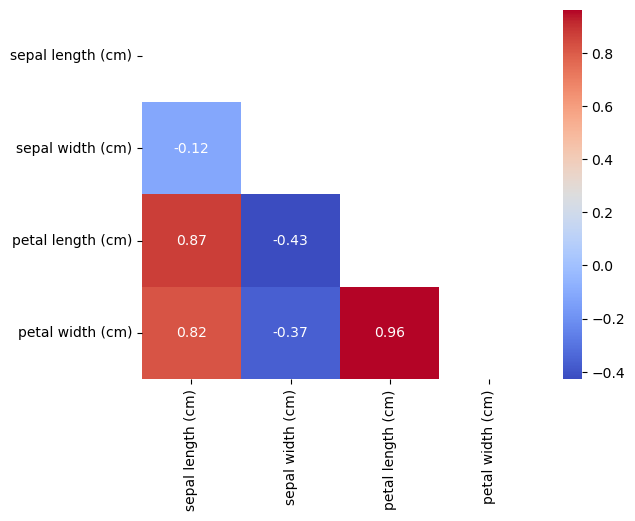

In [19]:
#Check the Co-relation between features without PCA
import numpy as np
# Generate a mask for the upper triangle
mask = np.triu(np.ones_like(scaled_data.corr(), dtype=bool))
sns.heatmap(scaled_data.corr(),mask=mask, annot=True, cmap='coolwarm')


Din harta termică de mai sus putem observa că lungimea sepalului și lungimea petalei și lungimea și lățimea petalei au o corelație mare. Astfel, evident că trebuie să aplicăm reducerea dimensionalității. Dacă știți deja că setul dvs. de date necesită reducerea dimensionalității - puteți sări peste acest pas.

`info point` Datele reprezintă un eșantion dintr-un spațiu numeric 4 dimensional. Geometric, un asemenea spațiu are o bază formată cu vectori unitate $(1,0,0,0), (0,1,0,0), (0,0,1,0), (0,0,0,1)$ cu care putem forma prin combinații liniare orice alt vector. PCA va forma o bază nouă, rotind norul de puncte într-un mod optim astfel încăt primele componente să fie pe direcțiile de alungire a norului. Există o mulțime de astfel de baze (gândiți-vă în câte moduri se pot roti axele în 2 dimensiuni, și mai mult, în 3 dimensiuni). O singură bază este însă optimă pentru setul de date avut în considerare. Ce se întâmplă dacă adăugăm date noi ține de cât de reprezentativ este setul de date inițial. Dacă e reprezentativ, atunci noile date nu diferă prea mult și un nou PCA nu ar schimba cu nimic datele problemei, deci putem proceda la transformarea datelor noi cu un model antrenat pe datele vechi.


## Pasul 4: Aplicarea analizei componentelor principale

 

Vom aplica PCA pe setul de date scalat. Pentru aceasta, Python oferă încă o clasă încorporată numită PCA, care este prezentă în sklearn.decomposition, pe care am importat-o deja în pasul 1. Trebuie să creăm un obiect de PCA și, în timp ce facem acest lucru, trebuie să inițializam și n_components - care este numărul de componente principale pe care le dorim în setul nostru de date final. Aici, am luat n_components = 3, ceea ce înseamnă că setul nostru final de caracteristici va avea 3 coloane. Ne potrivim/antrenăm datele scalate la obiectul PCA, ceea ce ne oferă setul nostru de date redus.

`Discuție` Care este numărul maxim de componente PCA pe care am putea să îl setăm?

In [21]:
#Apicăm PCA
#cu număr de Principal Components = 3
pca = PCA(n_components =4)
pca.fit(scaled_data)
data_pca = pca.transform(scaled_data)
data_pca = pd.DataFrame(data_pca,columns=['PC1','PC2','PC3','PC4'])
display(scaled_data)
data_pca.head()


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,-0.900681,1.019004,-1.340227,-1.315444
1,-1.143017,-0.131979,-1.340227,-1.315444
2,-1.385353,0.328414,-1.397064,-1.315444
3,-1.506521,0.098217,-1.283389,-1.315444
4,-1.021849,1.249201,-1.340227,-1.315444
...,...,...,...,...
145,1.038005,-0.131979,0.819596,1.448832
146,0.553333,-1.282963,0.705921,0.922303
147,0.795669,-0.131979,0.819596,1.053935
148,0.432165,0.788808,0.933271,1.448832


,PC1,PC2,PC3,PC4
0,-2.264703,0.480027,0.127706,-0.024168
1,-2.080961,-0.674134,0.234609,-0.103007
2,-2.364229,-0.341908,-0.044201,-0.028377
3,-2.299384,-0.597395,-0.091290,0.065956
4,-2.389842,0.646835,-0.015738,0.035923


## Pasul 5: Verificarea corelației dintre caracteristici după PCA

Acum că am aplicat PCA și am obținut setul de caracteristici redus, vom verifica corelația dintre diferitele Componente Principale, din nou folosind o hartă termică.


<Axes: >

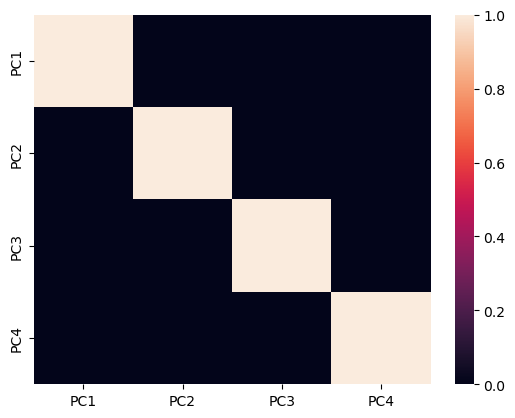

In [22]:
#verficăm noile corelații
sns.heatmap(data_pca.corr())


Harta termică de mai sus arată în mod clar că nu există o corelație între diferitele componente principale obținute (PC1, PC2 și PC3). Astfel, ne-am mutat de la un spațiu de caracteristici de dimensiuni mai mari la un spațiu de caracteristici de dimensiuni inferioare, asigurându-ne în același timp că nu există nicio corelație între PC-urile astfel obținute este minimă. Prin urmare, am îndeplinit obiectivele PCA.

Să vedem cum arată un biplot dar și un barchart cu varianța explicată de cele trei componente.

Cu această ocazie vom evalua și un modul alternativ, dedicat PCA.

In [ ]:
#! pip install pca

[pca] >Extracting column labels from dataframe.
[pca] >Extracting row labels from dataframe.
[pca] >The PCA reduction is performed on the [4] columns of the input dataframe.
[pca] >Fit using PCA.
[pca] >Compute loadings and PCs.
[pca] >Compute explained variance.
[pca] >Outlier detection using Hotelling T2 test with alpha=[0.05] and n_components=[4]
[pca] >Multiple test correction applied for Hotelling T2 test: [fdr_bh]
[pca] >Outlier detection using SPE/DmodX with n_std=[3]
[scatterd]> WARNING use the standardized verbose status. The status [1-6] will be deprecated in future versions.
[pca] >Plot PC1 vs PC2 with loadings.
[scatterd]> WARNING use the standardized verbose status. The status [1-6] will be deprecated in future versions.


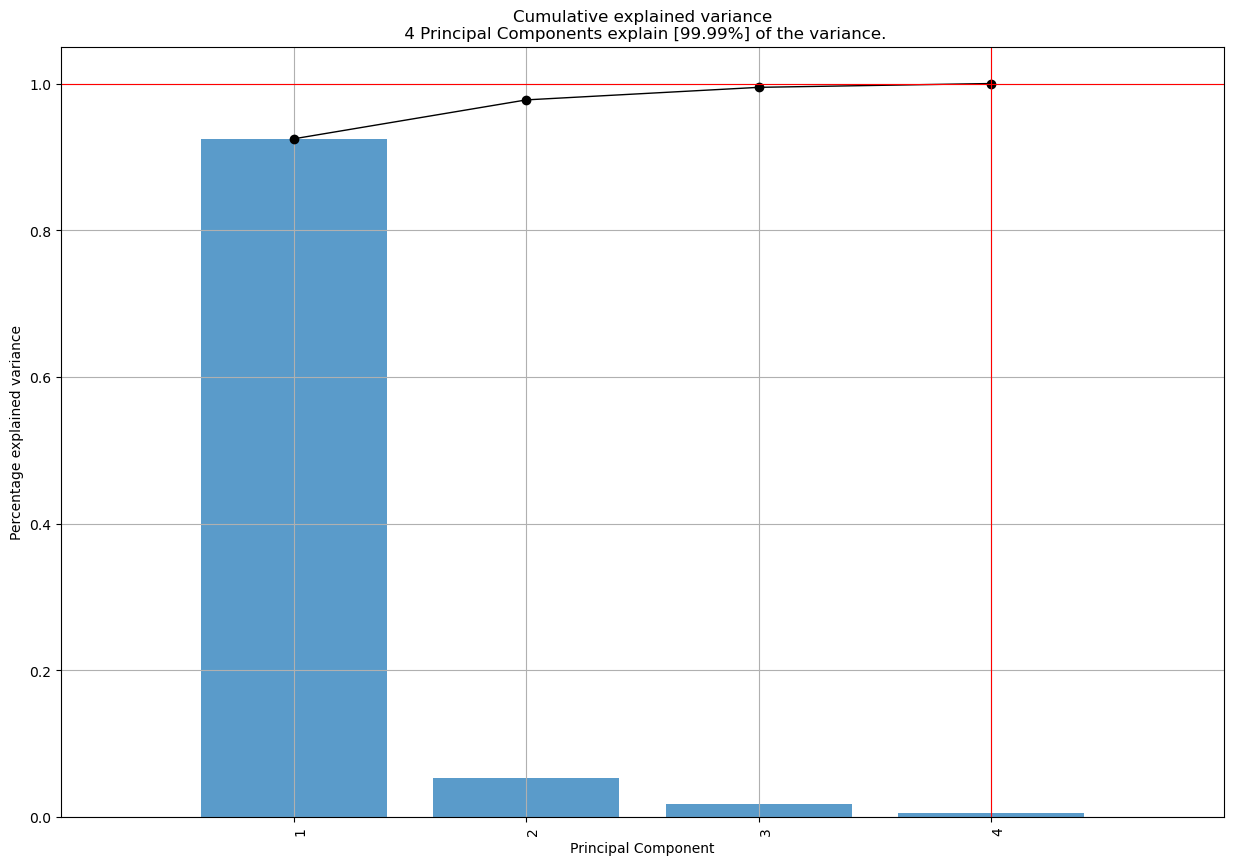

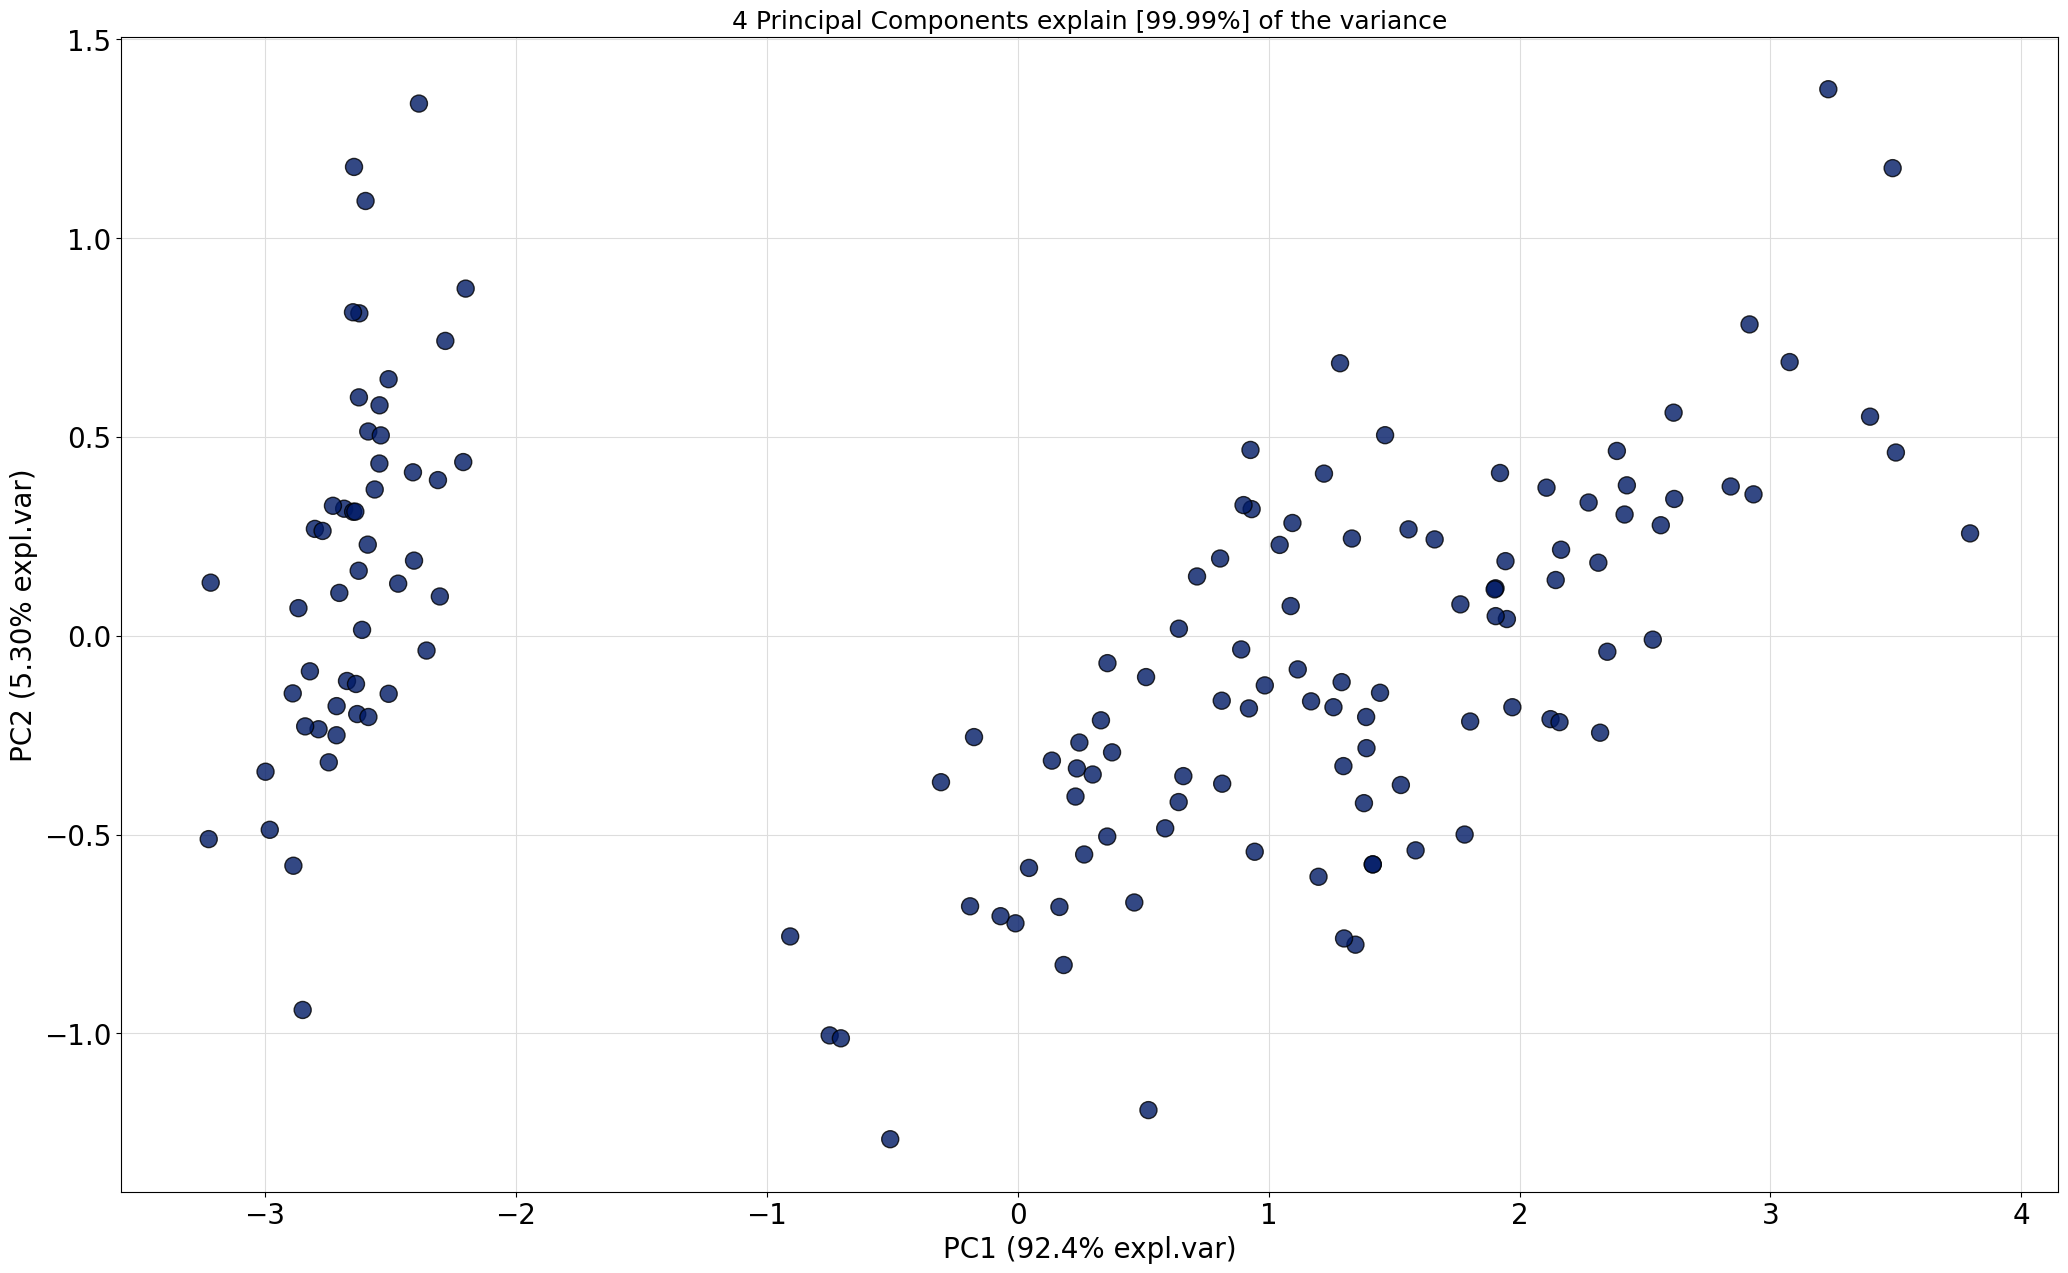

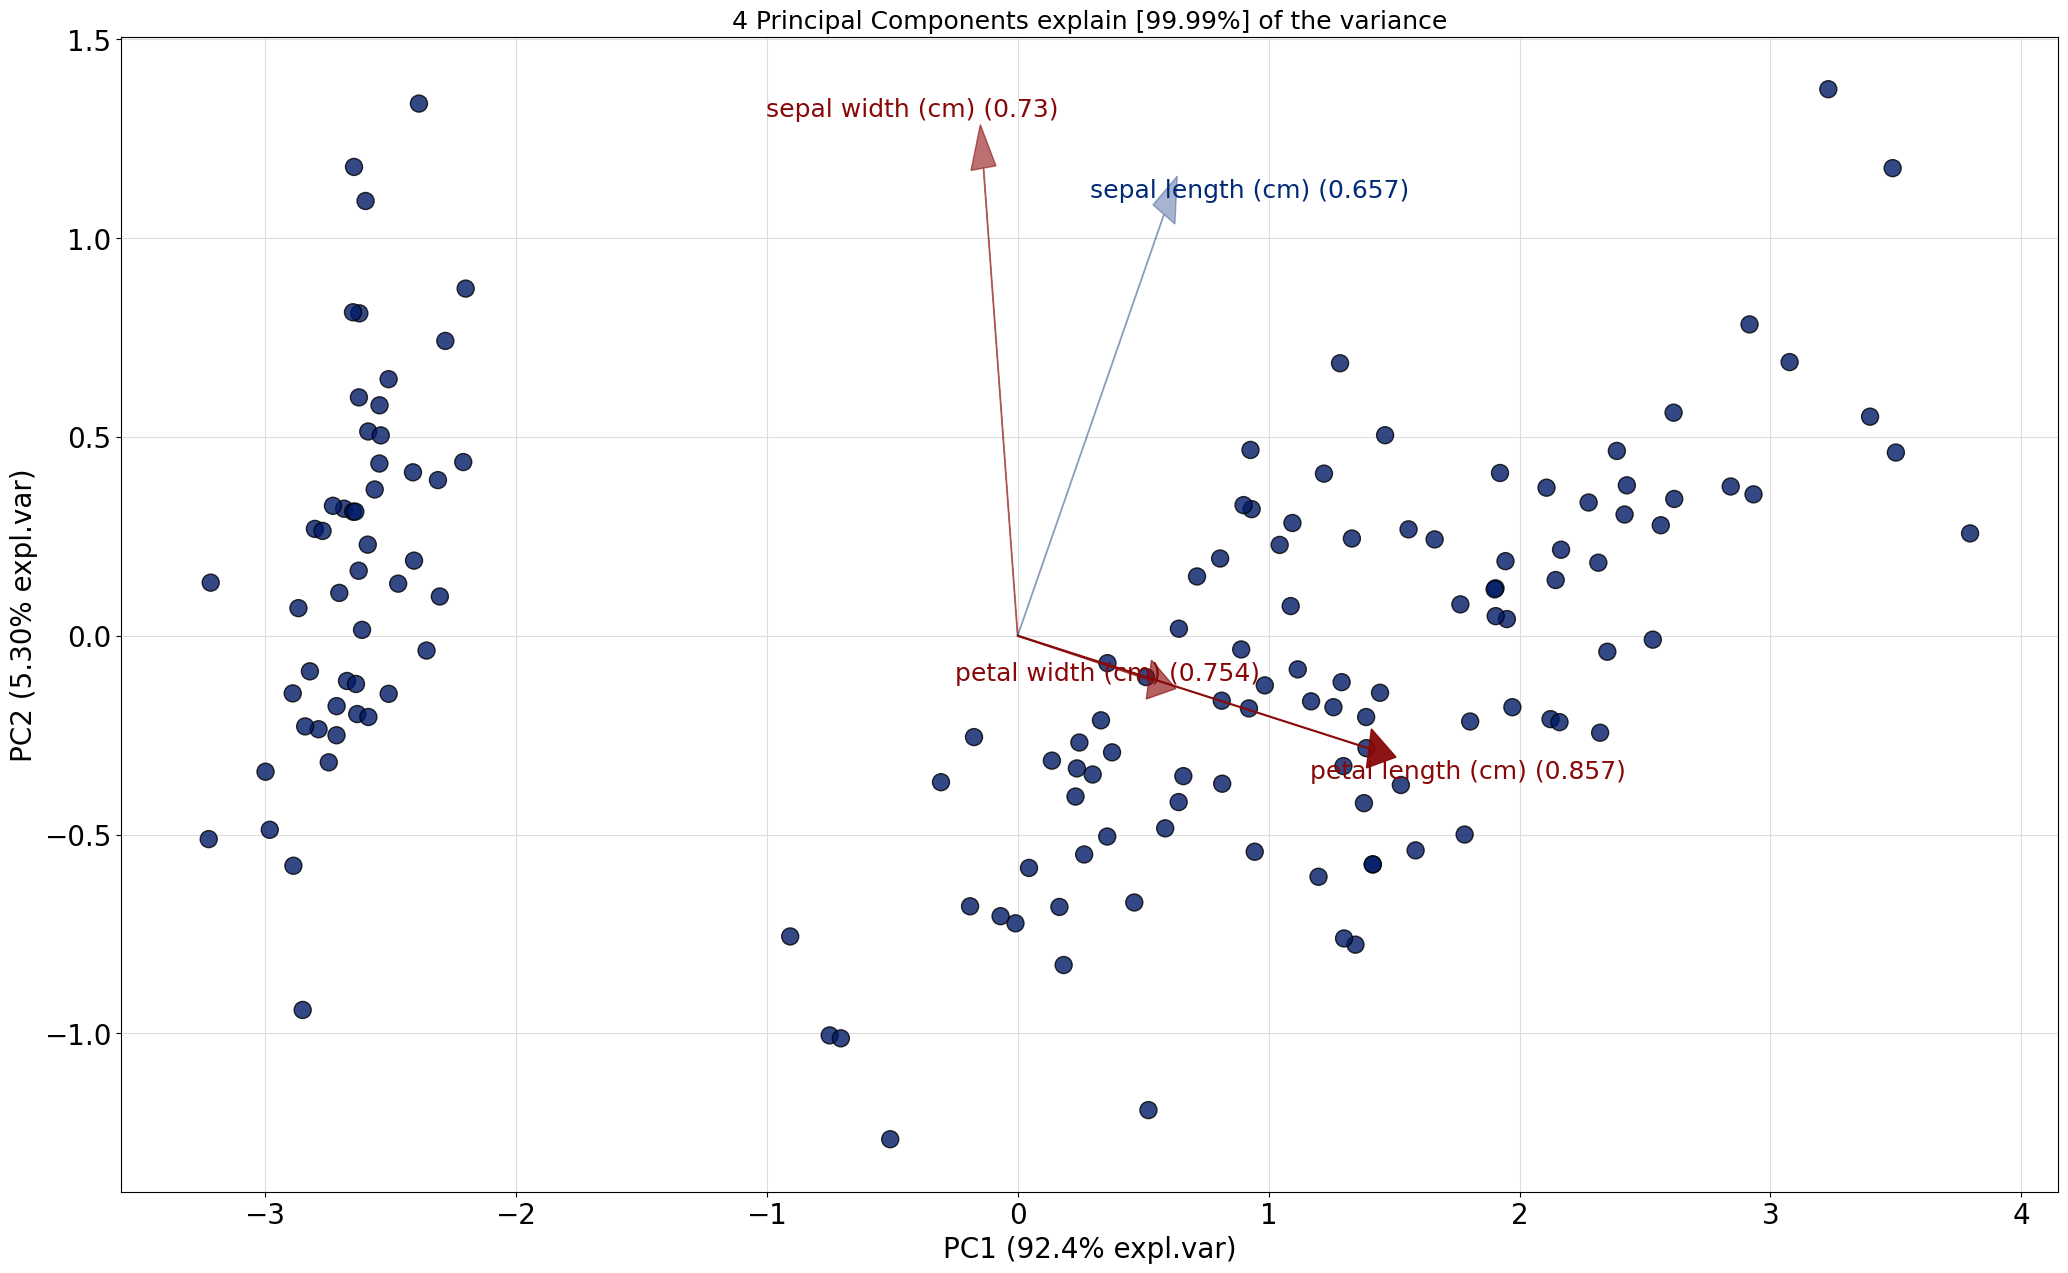

In [23]:
from pca import pca
# Instanțiem un obiect PCA
# putem alege între a reduce numărul de componente la cele care
# explică 95% din varianța totală 
# model = pca(n_components=0.95)
# ... sau putem set explicit numărul de componente dorite
model = pca(n_components=4)

# antrenare și transformare (deși am schimnbat modulul, numele metodei a rămas același!)
results = model.fit_transform(X=df)

# grafic de bare cu varianța explicată
fig, ax = model.plot()

# grqfic de împrăștiere (scatter plot) cu primele două componente
fig, ax = model.scatter()

# biplot
fig, ax = model.biplot(n_feat=4)

In [24]:
results['PC']

,PC1,PC2,PC3,PC4
0,-2.684126,0.319397,-0.027915,0.002262
1,-2.714142,-0.177001,-0.210464,0.099027
2,-2.888991,-0.144949,0.017900,0.019968
3,-2.745343,-0.318299,0.031559,-0.075576
4,-2.728717,0.326755,0.090079,-0.061259
...,...,...,...,...
145,1.944110,0.187532,0.177825,0.426196
146,1.527167,-0.375317,-0.121898,0.254367
147,1.764346,0.078859,0.130482,0.137001
148,1.900942,0.116628,0.723252,0.044595


In [25]:
# Extract the loadings (coefficients of eigenvectors)
results['loadings'].T

,PC1,PC2,PC3,PC4
sepal length (cm),0.361387,0.656589,-0.582030,0.315487
sepal width (cm),-0.084523,0.730161,0.597911,-0.319723
petal length (cm),0.856671,-0.173373,0.076236,-0.479839
petal width (cm),0.358289,-0.075481,0.545831,0.753657


`info point` În biplot vectorii etichetați cu numele coloanelor reprezintă cei 4 vectori unitate din spațiul de eșantionare, unde ei formează o bază ortonormată: au lungimea 1 și sunt perpendiculari doi câte doi. Ce vedem în biplot este o rotație în spațiul 4 dimensional urmată de o proiecție pe planul primelor două componente. După cum vedem originea e aceeiași.

### K-Means pe setul de date iris

In [26]:
import pandas as pd
import numpy as np

import seaborn as sns
from sklearn.cluster import KMeans 
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import MinMaxScaler
from sklearn.datasets import load_iris

In [27]:
iris = load_iris() #pd.read_csv("../input/iris-flower-dataset/IRIS.csv")
df_iris = pd.DataFrame(data= np.c_[iris['data'], iris['target']],
                     columns= iris['feature_names'] + ['target'])
df_iris = df_iris.assign(specie = df_iris.target.apply(lambda x: iris.target_names[int(x)]))
df_iris

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,specie
0,5.1,3.5,1.4,0.2,0.0,setosa
1,4.9,3.0,1.4,0.2,0.0,setosa
2,4.7,3.2,1.3,0.2,0.0,setosa
3,4.6,3.1,1.5,0.2,0.0,setosa
4,5.0,3.6,1.4,0.2,0.0,setosa
...,...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2.0,virginica
146,6.3,2.5,5.0,1.9,2.0,virginica
147,6.5,3.0,5.2,2.0,2.0,virginica
148,6.2,3.4,5.4,2.3,2.0,virginica


`info point` De la biologie, via internet:
  <img style="float: center;  width: 300px" src="https://raw.githubusercontent.com/prof/SEED/main/cursuri/03-invatare-nesupervizata/imagini/iris.jpg">
<center><b>Fig. Sepala și petala</b></center>

Să vedem distribuțiile metricilor din observații:

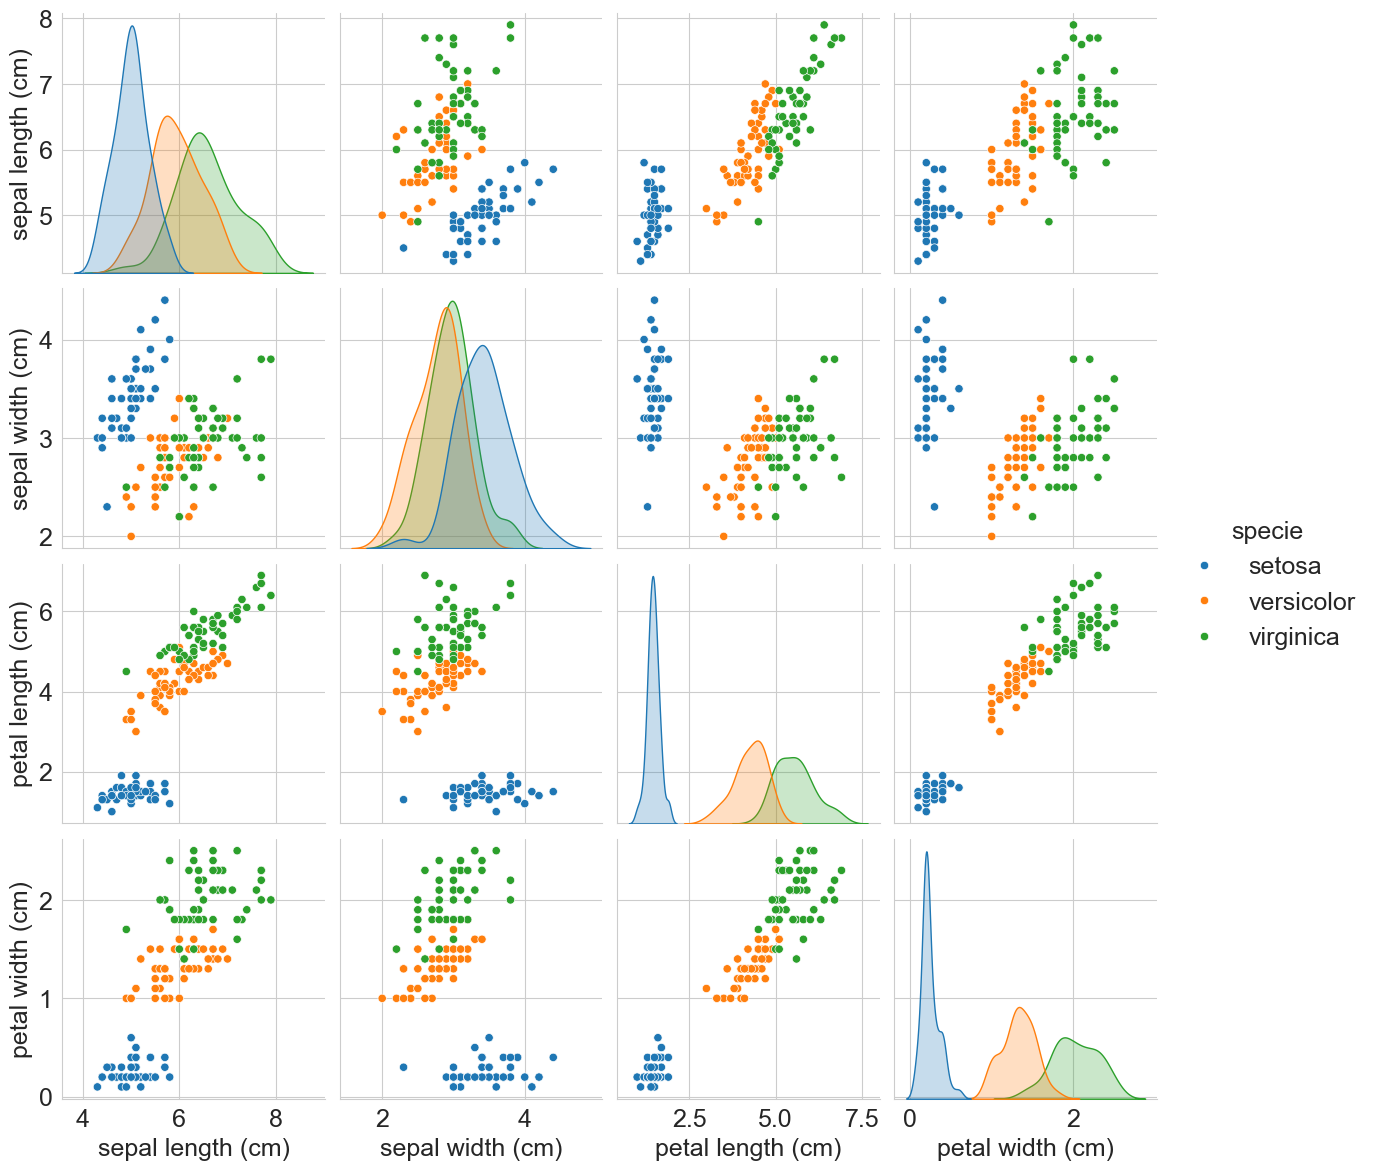

In [28]:
import matplotlib.pyplot as plt
sns.set_style("whitegrid")
sns.pairplot(df_iris[[c for c in df_iris.columns if c!='target']],hue="specie",height=3);
plt.show()

Să vedem distribuția pe specii

In [29]:
#df_iris.groupby('specie', as_index = False).targent.count()
df_iris.groupby('specie', as_index = False).agg( nr_observații = ('target','count'))

,specie,nr_observații
0,setosa,50
1,versicolor,50
2,virginica,50


Problema cu metodele nesupervizate de clusterizare: nu știm câte cluster căutăm. Există diverse metode heuristice pe care le putem trece în revistă:
- metoda 'cotului'
- metoda scorului siluetelor

Pentru prima metodă încercăm clusterizarea cu diverse numere de clustere și observăm prin inspecție grafică care ar fi numărul optim de clustere.

In [34]:
import os

# Setare variabile din mediul Python doar pentru aceasta sesiune Jupyter
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"
os.environ["OMP_NUM_THREADS"] = "1"


In [37]:
from sklearn.cluster import KMeans


# metoda de penalizare: suma distanțelor de la centroid la punctele din grup
wcss = [] #within cluster sum of squares

# încercăm diverse numere de grupe
for n_grupe in range(1, 11):
    kmeans = KMeans(n_clusters = n_grupe, # câte grupe se caută
                    init = 'k-means++', # metoda de selectare a primilor reprezentanți ai grupelor
                    max_iter = 300, # număr maxim de iterații prin recalcularea centroizilor
                    n_init = 10, # număr de rulări distincte ale algoritmului; se va reține cea mai bună rulare
                    random_state = 0) # o ancoră pentru alegere aleatorie dar fixă în vederea explorărilor cu repetiție
    kmeans.fit(df_iris[[c for c in df_iris.columns if c not in ['target','specie']]].values)
    wcss.append(kmeans.inertia_)

Folosim metoda cotului pentru a determina numărul optim de clustere pentru k-means

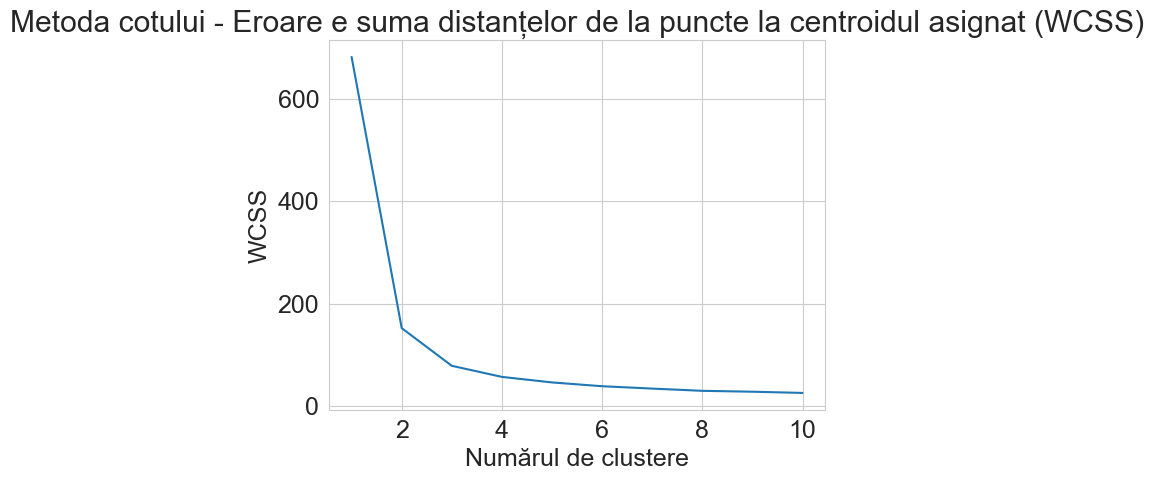

In [38]:
plt.plot(range(1, 11), wcss)
plt.title('Metoda cotului - Eroare e suma distanțelor de la puncte la centroidul asignat (WCSS)')
plt.xlabel('Numărul de clustere')
plt.ylabel('WCSS') #within cluster sum of squares
plt.show()

O valoare mică la WCSS este bună. Un număr prea mare de clustere nu e de dorit. 

După comportamentul erorii, ăncepând cu număr grupe = 4 nu se mai înregistrează reduceri substanțiale ale erorii. Deci un număr de 3 clase este ok.

#### Implementarea cu 3 grupe

In [39]:
kmeans = KMeans(n_clusters = 3, init = 'k-means++', max_iter = 300, n_init = 10, random_state = 0)
df_iris['y_kmeans'] = kmeans.fit_predict(df_iris[[c for c in df_iris.columns if c not in ['target','specie']]].values)
df_iris

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,specie,y_kmeans
0,5.1,3.5,1.4,0.2,0.0,setosa,1
1,4.9,3.0,1.4,0.2,0.0,setosa,1
2,4.7,3.2,1.3,0.2,0.0,setosa,1
3,4.6,3.1,1.5,0.2,0.0,setosa,1
4,5.0,3.6,1.4,0.2,0.0,setosa,1
...,...,...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2.0,virginica,2
146,6.3,2.5,5.0,1.9,2.0,virginica,0
147,6.5,3.0,5.2,2.0,2.0,virginica,2
148,6.2,3.4,5.4,2.3,2.0,virginica,2


In [40]:
df_iris = df_iris.assign( Succes =df_iris.target == df_iris.y_kmeans)
df_iris['Succes'] = df_iris['Succes'].astype(int)
df_iris_kmeans = df_iris.groupby(['specie','target','y_kmeans'], as_index = False).Succes.count()
df_iris_kmeans
#df_iris_kmeans.pivot(index = 'specie',columns = ['y_kmeans'], values ='Succes')

,specie,target,y_kmeans,Succes
0,setosa,0.0,1,50
1,versicolor,1.0,0,48
2,versicolor,1.0,2,2
3,virginica,2.0,0,14
4,virginica,2.0,2,36


In [ ]:
from sklearn.metrics import classification_report,confusion_matrix
print(confusion_matrix(y_true = df_iris.target, y_pred = [1 if x ==0 else 0 if x==1 else 2 for x in df_iris.y_kmeans.values]))
print(classification_report(df_iris.target, [1 if x ==0 else 0 if x==1 else 2 for x in df_iris.y_kmeans.values]))


[[50  0  0]
 [ 0 48  2]
 [ 0 14 36]]
              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00        50
         1.0       0.77      0.96      0.86        50
         2.0       0.95      0.72      0.82        50

    accuracy                           0.89       150
   macro avg       0.91      0.89      0.89       150
weighted avg       0.91      0.89      0.89       150



DBI

In [50]:
# Davie-Bouldain Index
df_iris.columns

Index(['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)',
       'petal width (cm)', 'target', 'specie', 'y_kmeans', 'Succes'],
      dtype='object')

Silhoutte score

In [51]:
X = df_iris[['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)',
       'petal width (cm)']]

for k in range(2,10):
    print( k,'-',
silhouette_score(X, KMeans(n_clusters = k, # câte grupe se caută
                    init = 'k-means++', # metoda de selectare a primilor reprezentanți ai grupelor
                    max_iter = 300, # număr maxim de iterații prin recalcularea centroizilor
                    n_init = 10, # număr de rulări distincte ale algoritmului; se va reține cea mai bună rulare
                    random_state = 0).fit_predict(X))
    )

2 - 0.6810461692117465
3 - 0.5528190123564101
4 - 0.4980505049972879
5 - 0.48874888709310615
6 - 0.36483400396700355
7 - 0.356861817253638
8 - 0.3597454923845772
9 - 0.33728465891200776
